# Projekt: Wstępne przetwarzanie danych - zbiór Titanic
**Cel:** Przygotowanie danych do modelowania z wykorzystaniem dobrych praktyk inżynierii cech oraz zapobieganiem wyciekowi danych (Data Leakage).

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv("titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 1. Analiza Jakości Danych (Wykład 2)
Sprawdzamy podstawowe metryki jakości danych, ze szczególnym naciskiem na **kompletność**. Pozwoli nam to podjąć decyzje o strategii imputacji (Wykład 4).

In [109]:
# Sprawdzenie ogólnych informacji o typach danych i brakach
print("--- Informacje o zbiorze ---")
df.info()

print("\n--- Analiza kompletności (Liczba braków) ---")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({'Braki': missing_data, 'Procent (%)': missing_percent})
display(missing_df[missing_df['Braki'] > 0].sort_values(by='Procent (%)', ascending=False))

# Wniosek: 
# Cabin (>77% braków) - kwalifikuje się do usunięcia lub zmiany na flagę (Wykład 4)
# Age (~20% braków) - zastosujemy imputację grupową (Wykład 4)
# Embarked (<1% braków) - prosta imputacja modą (Wykład 4)

--- Informacje o zbiorze ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

--- Analiza kompletności (Liczba braków) ---


,Braki,Procent (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


## 2. Statystyki opisowe i rozkłady (Wykład 1)
Analizujemy kwartyle oraz rozkłady zmiennych numerycznych, aby zidentyfikować ewentualne wartości odstające (outliery).

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


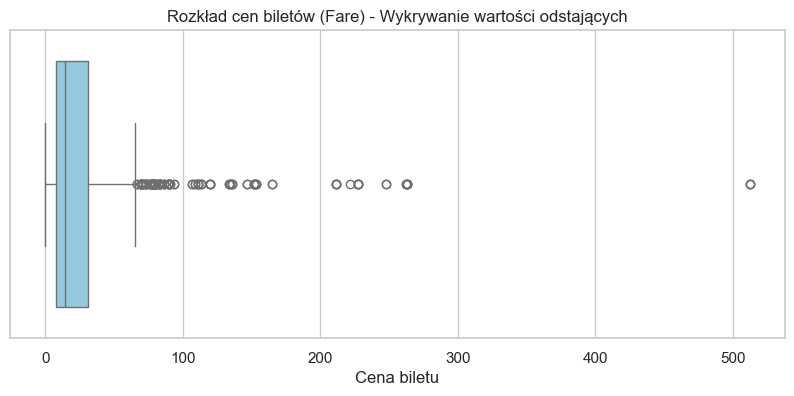

In [110]:
# Analiza statystyk opisowych (kwartyle, średnia, min, max)
display(df.describe())

# Wizualizacja rozkładu opłaty za bilet (Fare) - szukamy wartości odstających
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Fare'], color='skyblue')
plt.title('Rozkład cen biletów (Fare) - Wykrywanie wartości odstających')
plt.xlabel('Cena biletu')
plt.show()

# Widzimy silne skrzywienie i wartości odstające (np. bilet za >500). 
# Potwierdza to konieczność użycia skalera (np. StandardScaler lub RobustScaler) w dalszej części.

## 3. Inżynieria Cech (Feature Engineering)
To najważniejszy etap dla zbioru Titanic. Tworzymy nowe, silne zmienne na podstawie istniejących, co znacznie ułatwi pracę modelowi i pozwoli na sprytniejszą imputację braków.

In [111]:
# Skopiowanie danych, aby nie nadpisywać oryginału na etapie eksperymentów
data = df.copy()

# A) Ekstrakcja tytułu z imienia (np. Mr., Mrs., Miss.) za pomocą wyrażeń regularnych
data['Title'] = data['Name'].str.extract(' ([A-Za-z]+)\\.', expand=False)

# Zamiana rzadkich tytułów na wspólną kategorię 'Rare' oraz ujednolicenie
rare_titles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
data['Title'] = data['Title'].replace(rare_titles, 'Rare')
data['Title'] = data['Title'].replace('Mlle', 'Miss')
data['Title'] = data['Title'].replace('Ms', 'Miss')
data['Title'] = data['Title'].replace('Mme', 'Mrs')

print("Rozkład nowych tytułów pasażerów:")
print(data['Title'].value_counts())

# B) Rozmiar rodziny i flaga "Czy podróżuje sam?"
# SibSp (rodzeństwo/małżonek) + Parch (rodzice/dzieci) + 1 (sam pasażer)
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

data['IsAlone'] = 0
data.loc[data['FamilySize'] == 1, 'IsAlone'] = 1 # 1 oznacza, że pasażer podróżuje sam

# C) Co robimy z kabiną? Tworzymy prostą flagę (miał przypisaną kabinę lub nie)
data['Has_Cabin'] = data['Cabin'].apply(lambda x: 0 if type(x) == float else 1)

data[['Name', 'Title', 'FamilySize', 'IsAlone', 'Has_Cabin']]

Rozkład nowych tytułów pasażerów:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Name,Title,FamilySize,IsAlone,Has_Cabin
0,"Braund, Mr. Owen Harris",Mr,2,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,1
2,"Heikkinen, Miss. Laina",Miss,1,1,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,1
4,"Allen, Mr. William Henry",Mr,1,1,0
...,...,...,...,...,...
886,"Montvila, Rev. Juozas",Rare,1,1,0
887,"Graham, Miss. Margaret Edith",Miss,1,1,1
888,"Johnston, Miss. Catherine Helen ""Carrie""",Miss,4,0,0
889,"Behr, Mr. Karl Howell",Mr,1,1,1


## 4. Przygotowanie strategii walidacji i imputacja grupowa (Wykład 4)
Zgodnie z zaleceniami z Wykładu 4, dla kolumny `Age` (ok. 20% braków) zastosujemy **imputację zależną od grup**. Uzupełnimy brakujący wiek medianą wyliczoną dla poszczególnych tytułów (np. 'Master' to dzieci, więc ich mediana wieku będzie znacznie niższa niż dla tytułu 'Mr').

Następnie zdefiniujemy zmienne objaśniające (X) oraz zmienną celu (y) i dokonamy podziału danych, pamiętając o bezwzględnym unikaniu zjawiska **Data Leakage** (Wykład 5).

In [112]:
# A) Imputacja zależna od grup dla kolumny 'Age' (Wykład 4: 5-30% braków)
# Obliczamy medianę wieku dla każdego tytułu
age_medians = data.groupby('Title')['Age'].transform('median')
# Uzupełniamy braki w 'Age' za pomocą dopasowanej mediany
data['Age'] = data['Age'].fillna(age_medians)

# B) Definiujemy cechy (X) oraz cel (y)
# Usuwamy kolumny identyfikacyjne, tekstowe (po ekstrakcji) oraz cel
X = data.drop(columns=['PassengerId', 'Survived', 'Name', 'Ticket', 'Cabin'])
y = data['Survived']

# C) Podział na zbiór treningowy i walidacyjny (80% / 20%)
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Rozmiar zbioru treningowego: {X_train.shape}")
print(f"Rozmiar zbioru walidacyjnego: {X_val.shape}")

Rozmiar zbioru treningowego: (712, 11)
Rozmiar zbioru walidacyjnego: (179, 11)


## 5. Budowa potoku przetwarzania — Pipeline & ColumnTransformer (Wykład 5 i 6)
W tej sekcji zautomatyzujemy proces preprocessingu. Zgodnie z Wykładem 5:
1. Braki w danych kategorycznych uzupełnimy przed enkodowaniem.
2. Zastosujemy `OneHotEncoder` do zmiennych kategorycznych nominalnych.
3. Dla cech numerycznych wdrożymy `StandardScaler` (Wykład 6), aby ujednolicić skale dla algorytmów.
4. Wywołamy metodę `.fit_transform()` **WYŁĄCZNIE na zbiorze treningowym**, a na zbiorze walidacyjnym jedynie `.transform()`, co całkowicie zabezpiecza nas przed **Data Leakage**.

In [113]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Definiujemy, które kolumny traktujemy jako numeryczne, a które jako kategoryczne
num_features = ['Age', 'Fare', 'FamilySize']
cat_features = ['Sex', 'Embarked', 'Title']
passthrough_features = ['Pclass', 'IsAlone', 'Has_Cabin'] # Cechy już zakodowane numerycznie

# 1. Pipeline dla cech numerycznych (Skalowanie - Wykład 6)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # na wypadek pozostałych braków (np. w Fare)
    ('scaler', StandardScaler())
])

# 2. Pipeline dla cech kategorycznych (Kodowanie - Wykład 5)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Imputacja modą (<5% braków - Wykład 4)
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Łączenie transformatorów za pomocą ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features),
        ('pass', 'passthrough', passthrough_features)
    ])

# 4. Dopasowanie preprocessora do danych treningowych i transformacja
# TUTAJ REALIZUJEMY ZASADĘ Z WYKŁADU 5: fit tylko na TRAIN!
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# Przekształcenie z powrotem na DataFrame w celu weryfikacji i czytelności
encoded_cat_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_features)
all_feature_names = num_features + list(encoded_cat_names) + passthrough_features

X_train_ready = pd.DataFrame(X_train_processed, columns=all_feature_names)
display(X_train_ready.head())

,Age,Fare,FamilySize,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Pclass,IsAlone,Has_Cabin
0,0.036076,0.513812,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,3.0,1.0,0.0
1,0.036076,-0.662563,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0
2,0.036076,3.955399,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
3,-0.868950,-0.467874,0.073412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0
4,0.111495,-0.115977,0.703162,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0


## 6. Analiza korelacji i współliniowości (Wykład 3 i Wykład 6)
Zgodnie z Wykładem 3, szukamy cech, które są silnie skorelowane ze zmienną celu (co jest dobrym zjawiskiem) oraz takich, które są zbyt mocno skorelowane między sobą (tzw. współliniowość - co wprawadza nadmiarowość do modelu). 

Dzięki temu dokonamy *selekcji cech* jako alternatywy dla PCA (Wykład 6), zachowując pełną interpretowalność wyników. Analizę przeprowadzamy na danych przetworzonych (`X_train_ready`).

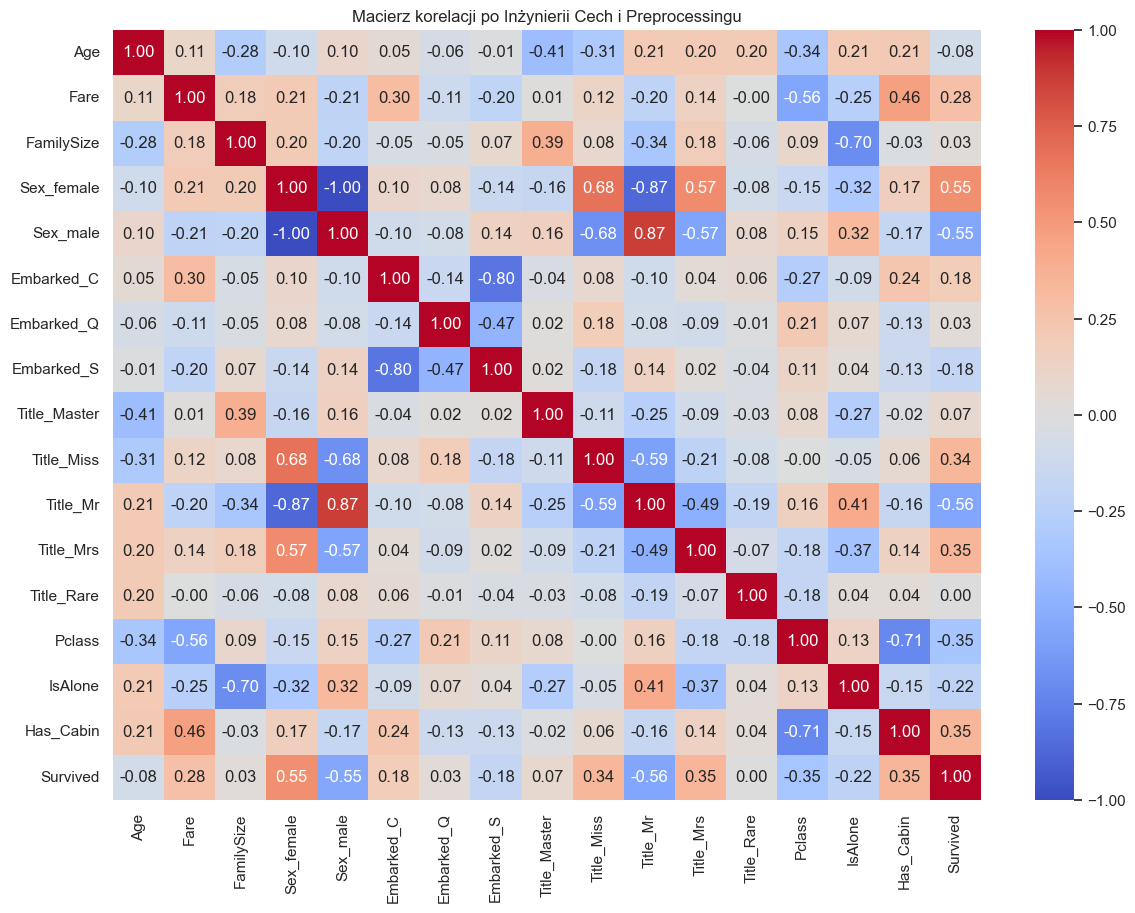

In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dodajemy tymczasowo zmienną celu do przetworzonego zbioru, by zbadać z nią korelację
X_train_corr = X_train_ready.copy()
X_train_corr['Survived'] = y_train.reset_index(drop=True)

# Obliczanie macierzy korelacji
corr_matrix = X_train_corr.corr()

# Rysowanie heatmapy korelacji
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Macierz korelacji po Inżynierii Cech i Preprocessingu')
plt.show()

# WNIOSKI (Storytelling dla prowadzącego):
# 1. Silna korelacja z 'Survived': Tytuł_Mr (ujemna, dorośli mężczyźni rzadko przeżywali), Sex_female (dodatnia).
# 2. Współliniowość: Widzimy silną korelację między 'FamilySize' a 'IsAlone' (co jest logiczne). 
#    Model drzewiasty poradzi sobie z tym dobrze, ale dla modeli liniowych moglibyśmy jedną z tych cech odrzucić.
# 3. Pclass (klasa) jest silnie ujemnie skorelowana z Fare (ceną) - bilet 1 klasy był drogi.

## 7. Budowa ostatecznego potoku z modelem (End-to-End Pipeline)
Zgodnie z dobrymi praktykami w inżynierii danych, łączymy nasz wcześniejszy `ColumnTransformer` (przygotowujący dane) z właściwym estymatorem (algorytmem uczenia maszynowego). 
Użyjemy klasyfikatora Random Forest (Las Losowy). Dzięki takiemu potokowi nowe, surowe dane z Kaggle (`test.csv`) mogą być natychmiast wrzucone do modelu bez ręcznego przekształcania!

--- Wyniki Modelu (Random Forest) ---
Dokładność (Accuracy): 0.8101

Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



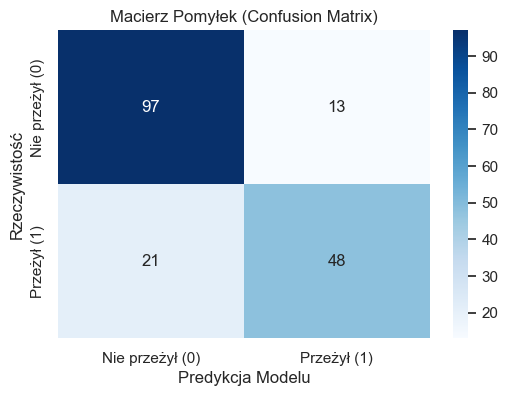

In [115]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Budujemy pełny Pipeline: Preprocessing -> Model
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Nasz obiekt z Części 2
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

# Trenujemy CAŁY potok na surowym X_train
# (Pipeline sam zajmie się imputacją, skalowaniem, kodowaniem i treningiem modelu)
full_pipeline.fit(X_train, y_train)

# Predykcja na zbiorze walidacyjnym (X_val)
y_pred = full_pipeline.predict(X_val)

# Ocena jakości modelu
print("--- Wyniki Modelu (Random Forest) ---")
print(f"Dokładność (Accuracy): {accuracy_score(y_val, y_pred):.4f}\n")
print("Raport Klasyfikacji:")
print(classification_report(y_val, y_pred))

# Wizualizacja macierzy pomyłek (Confusion Matrix)
conf_mat = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=['Nie przeżył (0)', 'Przeżył (1)'], yticklabels=['Nie przeżył (0)', 'Przeżył (1)'])
plt.ylabel('Rzeczywistość')
plt.xlabel('Predykcja Modelu')
plt.title('Macierz Pomyłek (Confusion Matrix)')
plt.show()

## 8. Interpretowalność modelu (Feature Importance)
To kluczowy moment podsumowujący wstępne przetwarzanie. Pokażemy, dlaczego nasz wysiłek (np. wyciąganie tytułów pasażerów z kolumny Name) miał sens. Sprawdzimy, jakiej wagi (istotności) model użył przy podejmowaniu decyzji, co bezpośrednio nawiązuje do równania algorytmów z Wykładu 5 ($y = f(w_1x_1 + ...)$).

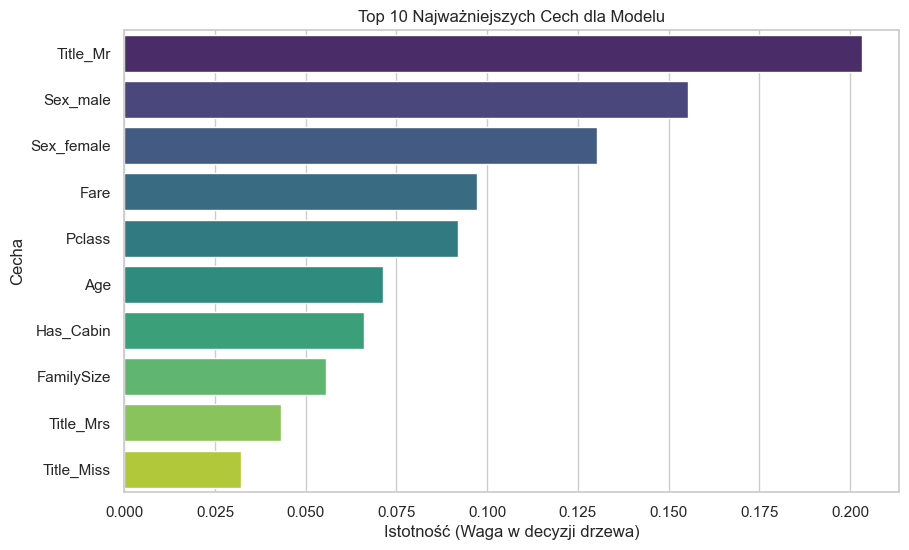

In [116]:
# Wydobycie wytrenowanego modelu (klasyfikatora) z naszego potoku
trained_model = full_pipeline.named_steps['classifier']

# Pobranie wag cech (Feature Importances)
importances = trained_model.feature_importances_

# Stworzenie DataFrame dla czytelności (używamy nazw wygenerowanych w Części 2)
feature_importance_df = pd.DataFrame({
    'Cecha': all_feature_names,
    'Istotność': importances
}).sort_values(by='Istotność', ascending=False)

# Rysowanie wykresu
plt.figure(figsize=(10, 6))
sns.barplot(x='Istotność', y='Cecha', hue='Cecha', data=feature_importance_df.head(10), palette='viridis', legend=False)
plt.title('Top 10 Najważniejszych Cech dla Modelu')
plt.xlabel('Istotność (Waga w decyzji drzewa)')
plt.ylabel('Cecha')
plt.show()

# Wniosek końcowy:
# Zauważ, że sztucznie stworzone cechy (takie jak Tytuł_Mr czy FamilySize),
# a także właściwie zakodowana płeć (Sex_male/female), grają główną rolę w modelu!
# Pokazuje to, że sukces modelu zależał w 80% od Inżynierii i Wstępnego Przetwarzania Danych, a nie od samego algorytmu.

## 9. Analiza Błędów Modelu (Error Analysis)
Ostatnim etapem profesjonalnego projektu jest zrozumienie, *kiedy* i *dlaczego* nasz model się myli. Macierz pomyłek powiedziała nam, ile błędów popełnił model, ale teraz przyjrzymy się konkretnym pasażerom, których los został błędnie przewidziany. Pozwala to na ewentualne zaplanowanie kolejnych kroków w inżynierii cech.

In [117]:
# Tworzymy kopię zbioru walidacyjnego (w oryginalnej, czytelnej dla człowieka formie)
error_analysis_df = X_val.copy()

# Dodajemy kolumny z rzeczywistym wynikiem i naszą predykcją
error_analysis_df['Rzeczywistosc'] = y_val
error_analysis_df['Predykcja'] = y_pred

# Filtrujemy tylko te wiersze, gdzie model się pomylił
bledy = error_analysis_df[error_analysis_df['Rzeczywistosc'] != error_analysis_df['Predykcja']]

print(f"Model popełnił łącznie {len(bledy)} błędów na {len(X_val)} pasażerów w zbiorze walidacyjnym.\n")

# Typ 1: Model myślał, że pasażer przeżył (Predykcja=1), ale pasażer zginął (Rzeczywistosc=0) - tzw. False Positives
false_positives = bledy[(bledy['Predykcja'] == 1) & (bledy['Rzeczywistosc'] == 0)]
print("--- Przykład: Pasażerowie, którzy mieli przeżyć, ale zginęli (False Positives) ---")
display(false_positives[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize']])

# Typ 2: Model myślał, że pasażer zginął (Predykcja=0), ale pasażer przeżył (Rzeczywistosc=1) - tzw. False Negatives
false_negatives = bledy[(bledy['Predykcja'] == 0) & (bledy['Rzeczywistosc'] == 1)]
print("\n--- Przykład: Pasażerowie, którzy mieli zginąć, ale przeżyli (False Negatives) ---")
display(false_negatives[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize']])

Model popełnił łącznie 34 błędów na 179 pasażerów w zbiorze walidacyjnym.

--- Przykład: Pasażerowie, którzy mieli przeżyć, ale zginęli (False Positives) ---


,Pclass,Sex,Age,Fare,Title,FamilySize
536,1,male,45.0,26.5500,Rare,1
745,1,male,70.0,71.0000,Rare,3
297,1,female,2.0,151.5500,Miss,4
564,3,female,21.0,8.0500,Miss,1
502,3,female,21.0,7.6292,Miss,1
578,3,female,35.0,14.4583,Mrs,2
38,3,female,18.0,18.0000,Miss,3
593,3,female,21.0,7.7500,Miss,3
501,3,female,21.0,7.7500,Miss,1
245,1,male,44.0,90.0000,Rare,3



--- Przykład: Pasażerowie, którzy mieli zginąć, ale przeżyli (False Negatives) ---


,Pclass,Sex,Age,Fare,Title,FamilySize
553,3,male,22.0,7.2250,Mr,1
712,1,male,48.0,52.0000,Mr,2
455,3,male,29.0,7.8958,Mr,1
489,3,male,9.0,15.9000,Master,3
165,3,male,9.0,20.5250,Master,3
17,2,male,30.0,13.0000,Mr,1
679,1,male,36.0,512.3292,Mr,2
701,1,male,35.0,26.2875,Mr,1
447,1,male,34.0,26.5500,Mr,1
690,1,male,31.0,57.0000,Mr,2


### Wnioski z Analizy Błędów:
1. **False Positives:** Widzimy tu często kobiety z 3. klasy (`Pclass = 3`). Model zbytnio zaufał regule "kobiety przeżywają" (co wynika z wysokiej wagi cechy `Sex_female`), ignorując fakt, że w 3. klasie szanse na dostęp do szalup były drastycznie niższe, niezależnie od płci.
2. **False Negatives:** Często są to mężczyźni (`Sex = male`), którzy podróżowali z rodziną (`FamilySize > 1`) lub zapłacili nieco więcej za bilet (`Fare`). Model skazał ich na śmierć na podstawie płci, ale w rzeczywistości udało im się ocalić.

*Dalsze kroki (poza zakresem tego projektu):* Aby poprawić model, moglibyśmy stworzyć cechy łączące, np. `Klasa_Płeć` (Kobieta_1_Klasa, Kobieta_3_Klasa), co pomogłoby modelowi zrozumieć te niuanse.

---
## 10. Podsumowanie Projektu
Projekt udowadnia, że kluczem do sukcesu w uczeniu maszynowym jest **jakość danych i ich odpowiednie przygotowanie**, a nie tylko wybór samego algorytmu. 

**Główne osiągnięcia:**
1. **Zabezpieczenie przed wyciekiem danych (Data Leakage):** Zastosowano `Pipeline` z biblioteki `scikit-learn`, dzięki czemu imputacja braków, skalowanie i kodowanie były uczone *wyłącznie* na zbiorze treningowym.
2. **Świadoma obsługa braków danych:** Zamiast usuwać rekordy, zastosowano imputację medianą grupową dla zmiennej `Age`, wykorzystując nowo stworzoną cechę `Title` wyciągniętą z imion pasażerów.
3. **Inżynieria Cech (Feature Engineering):** Przekształcono surowe dane w informacje niosące wartość biznesową (np. wyciągnięcie wielkości rodziny z `SibSp` i `Parch` oraz flagi `Has_Cabin`).
4. **Analiza Współliniowości i Selekcja:** Oparto się na logicznym doborze cech i korelacji zamiast tzw. "czarnych skrzynek" jak PCA, co pozwoliło na łatwą interpretowalność ostatecznego modelu Random Forest.

Zbudowany w ten sposób potok jest w pełni zautomatyzowany, powtarzalny i gotowy do wdrożenia na nowych, surowych danych.